In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import minimum_spanning_tree


In [2]:
# Load and scale the dataset
data_path = "../data/clustering_dataset.csv"
df = pd.read_csv(data_path)

scaler = StandardScaler()
X = scaler.fit_transform(df.values)

print(f"Data Loaded and Scaled. Shape: {X.shape}")

Data Loaded and Scaled. Shape: (12000, 2)


In [ ]:
class HDBSCAN:
    def __init__(self, min_cluster_size=120, min_samples=25):
        self.min_cluster_size = min_cluster_size
        self.min_samples = min_samples
        self.labels_ = None
        self.mst_ = None
        self.core_dists_ = None

    def fit(self, X):
        n = X.shape[0]
        
        # 1. CORE DISTANCES (Density Estimation)
        nbrs = NearestNeighbors(n_neighbors=self.min_samples).fit(X)
        distances, indices = nbrs.kneighbors(X)
        self.core_dists_ = distances[:, -1] 

        # 2. MUTUAL REACHABILITY GRAPH
        # Connecting each point to its k-neighbors using MRD
        rows, cols, data = [], [], []
        for i in range(n):
            for j_idx, d in zip(indices[i], distances[i]):
                if i == j_idx: continue
                # MRD = max(core_dist_a, core_dist_b, raw_distance)
                # Builds a graph where edge weights = mutual reachability distance (MRD):
                mreach = max(self.core_dists_[i], self.core_dists_[j_idx], d)
                rows.append(i)
                cols.append(j_idx)
                data.append(mreach)

        # 3. MINIMUM SPANNING TREE (MST)
        graph = coo_matrix((data, (rows, cols)), shape=(n, n))
        self.mst_ = minimum_spanning_tree(graph)
        
        # 4. HIERARCHY BUILDING (Edge Sorting)
        # Extracts MST edges.
        # Sort edges by weight (MRD) ascending to prepare cluster hierarchy.
        mst_rows, mst_cols = self.mst_.nonzero()
        mst_data = self.mst_.data
        edges = sorted(zip(mst_data, mst_rows, mst_cols), key=lambda x: x[0])

        # Union-Find for Cluster Extraction|find(i) → tells us which cluster a point belongs to.
        parent = np.arange(n)
        def find(i):
            while parent[i] != i:
                parent[i] = parent[parent[i]]
                i = parent[i]
            return i

        # Step 5: CONDENSED TREE EXTRACTION (Heuristic Cut)
        # Cutting top 2% of edges (longest) which typically represent noise bridges
        threshold = np.percentile(mst_data, 98) 

        # Go through all edges shorter than threshold.
        for w, u, v in edges:
            if w <= threshold:
                root_u, root_v = find(u), find(v)
                if root_u != root_v:
                    parent[root_v] = root_u

        # Assign Labels
        raw_labels = np.array([find(i) for i in range(n)])
        unique_roots = np.unique(raw_labels)
        
        final_labels = np.full(n, -1)
        cluster_id = 0
        for root in unique_roots:
            member_indices = np.where(raw_labels == root)[0]
            # Stability Check: Minimum Cluster Size filter
            if len(member_indices) >= self.min_cluster_size:
                final_labels[member_indices] = cluster_id
                cluster_id += 1
                
        self.labels_ = final_labels
        return self

In [4]:
MIN_CLUSTER_SIZE = 50 
MIN_SAMPLES = 25

start_time = time.time()
model = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES)
model.fit(X)
run_time = time.time() - start_time

labels = model.labels_
n_clusters = len(np.unique(labels[labels != -1]))
n_noise = np.sum(labels == -1)

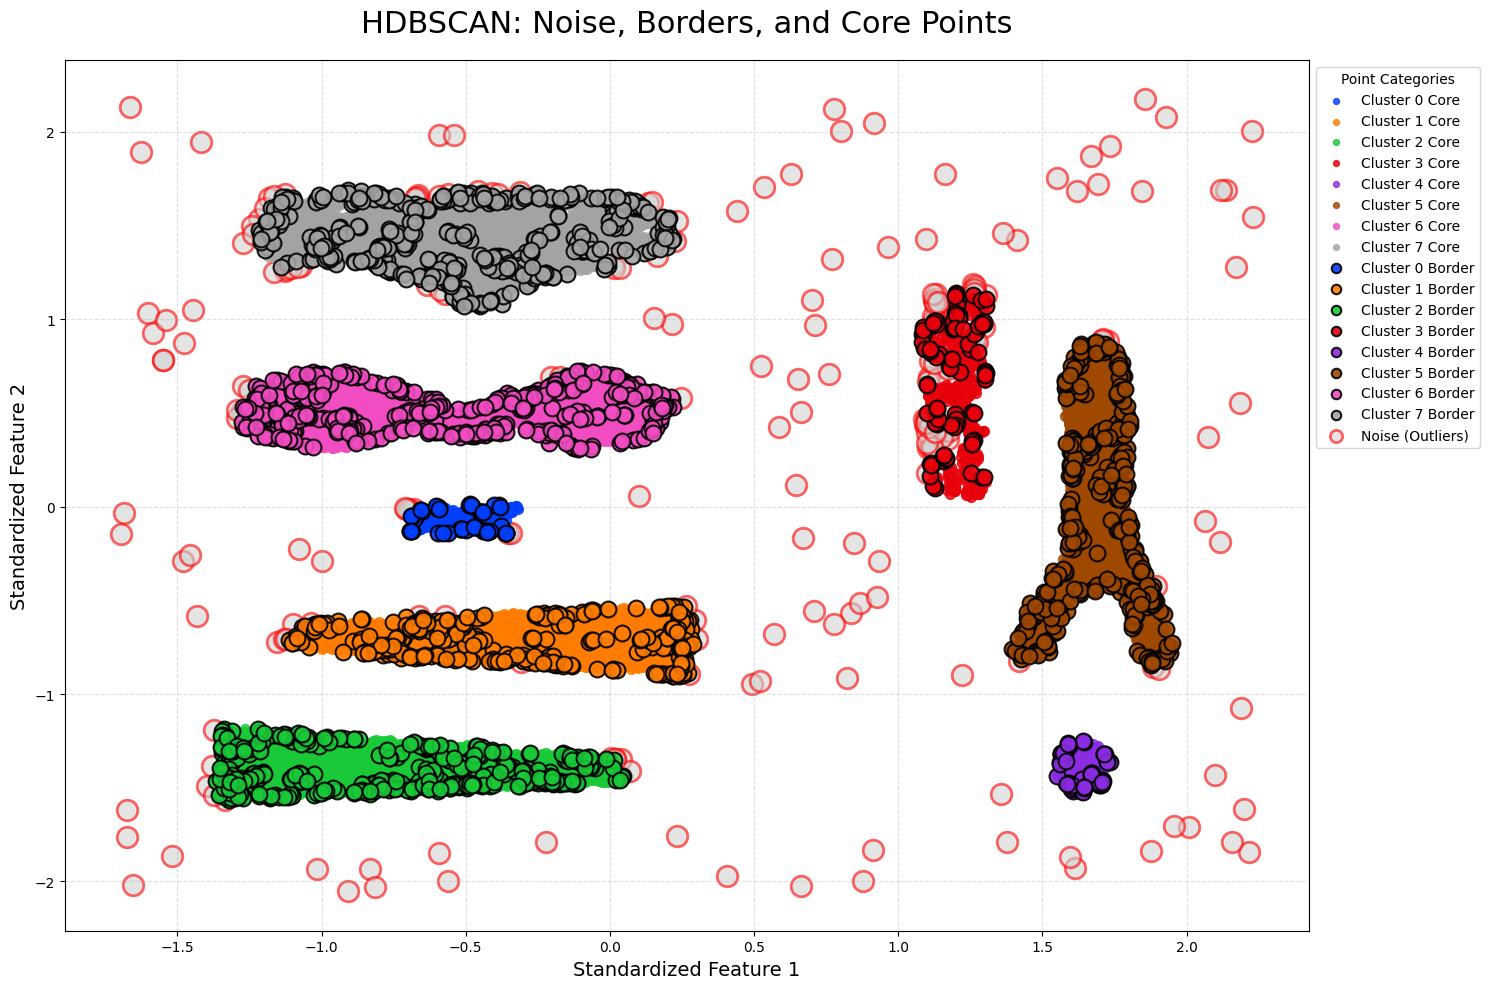

In [6]:
# 1. Prepare Categorization
unique_clusters = np.unique(labels[labels != -1])
is_noise = (labels == -1)
is_border = np.zeros(X.shape[0], dtype=bool)
is_core = np.zeros(X.shape[0], dtype=bool)

# For each cluster, define the 20% most 'sparse' points as Borders
for cluster_id in unique_clusters:
    idx = np.where(labels == cluster_id)[0]
    cluster_core_dists = model.core_dists_[idx]
    threshold = np.percentile(cluster_core_dists, 80)
    is_border[idx[cluster_core_dists >= threshold]] = True
    is_core[idx[cluster_core_dists < threshold]] = True

# 2. Plotting
plt.figure(figsize=(15, 10))
palette = sns.color_palette("bright", len(unique_clusters))

# Plot Core Points (Normal size)
for i, l in enumerate(unique_clusters):
    mask = (labels == l) & is_core
    plt.scatter(X[mask, 0], X[mask, 1], color=palette[i], s=50, 
                label=f'Cluster {l} Core', alpha=0.8, zorder=2)

# Plot Border Points (Large, Cluster Color, Black Edge)
for i, l in enumerate(unique_clusters):
    mask = (labels == l) & is_border
    plt.scatter(X[mask, 0], X[mask, 1], color=palette[i], s=130, 
                edgecolors='black', linewidth=1.5, label=f'Cluster {l} Border', alpha=0.9, zorder=3)

# Plot Noise (Very Large, Grey Fill, Red Edge)
plt.scatter(X[is_noise, 0], X[is_noise, 1], color='lightgrey', s=220, 
            edgecolors='red', linewidth=2.0, label='Noise (Outliers)', alpha=0.6, zorder=1)

# 3. Final Styling
plt.title("HDBSCAN: Noise, Borders, and Core Points", fontsize=22, pad=20)
plt.legend(markerscale=0.6, loc='upper left', bbox_to_anchor=(1, 1), title="Point Categories")
plt.xlabel("Standardized Feature 1", fontsize=14)
plt.ylabel("Standardized Feature 2", fontsize=14)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [7]:


# Metric calculation - Masking noise points to evaluate cluster quality
mask = labels != -1
if n_clusters > 1:
    sil = silhouette_score(X[mask], labels[mask])
    db = davies_bouldin_score(X[mask], labels[mask])
    ch = calinski_harabasz_score(X[mask], labels[mask])
else:
    sil = db = ch = np.nan

# Logging to results.csv
results_path = "../results.csv"
res_df = pd.DataFrame([{
    "model": "hdbscan", 
    "n_clusters": n_clusters, 
    "epsilon": "N/A", 
    "min_pts": MIN_SAMPLES,
    "inertia": 0, 
    "silhouette": sil, 
    "davies_bouldin_score": db, 
    "calinski_harabasz_score": ch, 
    "n_noise": n_noise, 
    "run_time": run_time
}])
res_df.to_csv(results_path, mode='a', header=not os.path.exists(results_path), index=False)

print(f"--- HDBSCAN COMPLETE ---")
print(f"Clusters: {n_clusters} | Noise: {n_noise} | Time: {run_time:.2f}s")
print(f"Silhouette (Filtered): {sil:.4f}")

--- HDBSCAN COMPLETE ---
Clusters: 8 | Noise: 233 | Time: 1.49s
Silhouette (Filtered): 0.4136
